# BO Replay Experiment (New Spec + Verbose)

Uses `BCLFOptimizationSpec(...).to_objective()` and `ReplayOptimizer(..., verbose=True)`.

In [27]:
from __future__ import annotations

from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import yaml

# Ensure repo src/ is importable
CWD = Path.cwd().resolve()
if (CWD / 'src').exists():
    REPO_ROOT = CWD
elif (CWD.parent / 'src').exists():
    REPO_ROOT = CWD.parent
else:
    raise RuntimeError(f'Cannot locate repo root from cwd={CWD}')

sys.path.insert(0, str(REPO_ROOT / 'src'))


from optimization.datasets import BCLFDataset
from optimization.optimization_spec import BCLFOptimizationSpec
from optimization.recorder import ExperimentRecorder
from optimization.replay_optimizer import ReplayOptimizer, RandomSearchOptimizer
from optimization.simulators import ReplaySimulator

In [28]:
# Paths
CONFIG_PATH = REPO_ROOT / 'configs' / 'filter_bnn_online_uaw_uaw.yaml'
DATASET_PATH = REPO_ROOT / 'data' / 'filter_bnn_online_uaw_uaw_dataset.pkl'
if not DATASET_PATH.exists():
    DATASET_PATH = REPO_ROOT / 'data' / 'bclf_dataset.pkl'
OUTPUT_DIR = REPO_ROOT / 'experiments' / 'bo_replay'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Experiment config
RUN_ID = 'bo_replay_experiment_latest_nb'
SEED = 3
N_INIT = 8
BUDGET = 40
RETRAIN_EVERY = 1

# Verbose controls
VERBOSE = False
PRINT_EVERY = 1

print('repo root:', REPO_ROOT)
print('config:', CONFIG_PATH, 'exists=', CONFIG_PATH.exists())
print('dataset:', DATASET_PATH, 'exists=', DATASET_PATH.exists())
print('output:', OUTPUT_DIR)
print('run_id:', RUN_ID)

repo root: /home/zhanghf/projects/vector
config: /home/zhanghf/projects/vector/configs/filter_bnn_online_uaw_uaw.yaml exists= True
dataset: /home/zhanghf/projects/vector/data/filter_bnn_online_uaw_uaw_dataset.pkl exists= True
output: /home/zhanghf/projects/vector/experiments/bo_replay
run_id: bo_replay_experiment_latest_nb


In [29]:
with CONFIG_PATH.open('r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)
freq_cfg = cfg['data']['freqs']
freqs = np.arange(freq_cfg['min'], freq_cfg['max'], freq_cfg['step'], dtype=float)

dataset = BCLFDataset.from_pickle(DATASET_PATH, freqs=freqs)

spec = BCLFOptimizationSpec(
    passband_ghz=(5.2, 5.9),
    lower_stopband_ghz=(3.6, 4.8),
    upper_stopband_ghz=(6.5, 8.7),
    min_passband_s21_db=-5.0,
    max_passband_s11_db=-5.0,
    max_stopband_s21_db=-15.0,
    s11_weight=0.5,
    stopband_weight=0.5,
)
objective = spec.to_objective()

print('freq points:', len(freqs), 'range_hz=', (float(freqs.min()), float(freqs.max())))
print('dataset size:', len(dataset))
print(json.dumps(objective.describe(), indent=2, ensure_ascii=False))

freq points: 401 range_hz= (3500000000.0, 8700000000.0)
dataset size: 1323
{
  "type": "objective_function",
  "minimize": true,
  "terms": [
    {
      "name": "score_a_mean_passband_s21",
      "kind": "MaximizeMetric",
      "metric": "s21_mean_5200000000_5900000000",
      "weight": 1.0
    },
    {
      "name": "score_b_mean_passband_s11",
      "kind": "MinimizeMetric",
      "metric": "s11_mean_5200000000_5900000000",
      "weight": 0.5
    },
    {
      "name": "score_c_mean_stopband_s21",
      "kind": "MinimizeMetric",
      "metric": "s21_mean_union_3600000000_4800000000__6500000000_8700000000",
      "weight": 0.5
    },
    {
      "name": "penalty_a_worst_passband_s21",
      "kind": "LowerBoundHingePenalty",
      "metric": "s21_min_5200000000_5900000000",
      "weight": 5.0
    },
    {
      "name": "penalty_b_worst_passband_s11",
      "kind": "UpperBoundHingePenalty",
      "metric": "s11_max_5200000000_5900000000",
      "weight": 5.0
    },
    {
      "name":

In [30]:
all_indices = np.arange(len(dataset), dtype=int)
rng = np.random.default_rng(SEED)
shuffled = all_indices.copy()
rng.shuffle(shuffled)
initial_indices = shuffled[:N_INIT].tolist()
candidate_indices = shuffled.tolist()
print('num initial:', len(initial_indices))
print('num candidates (including init):', len(candidate_indices))


num initial: 8
num candidates (including init): 1323


In [31]:
# Live plotting callback (updates during optimizer.run())
import matplotlib.pyplot as plt
from IPython.display import clear_output

def live_plot_cb(trial, history):
    iters = [r['iteration'] for r in history]
    objs = [r['objective'] for r in history]
    best = [r['best_so_far'] for r in history]

    clear_output(wait=True)
    fig, ax = plt.subplots(1, 1, figsize=(8, 4.5))
    ax.plot(iters, objs, marker='o', label='objective', alpha=0.85)
    ax.plot(iters, best, marker='o', label='best_so_far', linewidth=2)
    ax.set_title('Live Replay Optimization')
    ax.set_xlabel('iteration')
    ax.set_ylabel('objective (minimize)')
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [32]:
simulator = ReplaySimulator(dataset=dataset)
recorder = ExperimentRecorder(output_dir=OUTPUT_DIR)

optimizer = ReplayOptimizer(
    dataset=dataset,
    simulator=simulator,
    objective=objective,
    recorder=recorder,
    initial_indices=initial_indices,
    candidate_indices=candidate_indices,
    budget=BUDGET,
    retrain_every=RETRAIN_EVERY,
    n_init=N_INIT,
    seed=SEED,
    run_id=RUN_ID,
    verbose=VERBOSE,
    print_every=PRINT_EVERY,
    progress_callback=live_plot_cb,
)

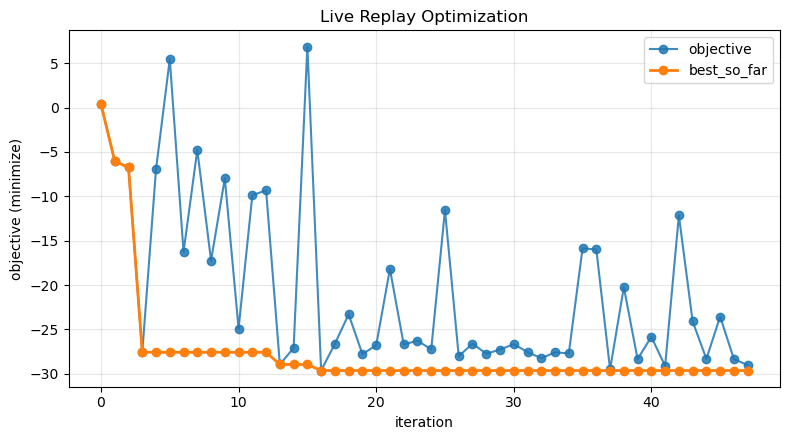

Run completed
run_id: bo_replay_experiment_latest_nb
num_trials: 48
best_objective: -29.642446245707813
best_index: 235
csv: /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_latest_nb.csv
json: /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_latest_nb.json


In [33]:
result = optimizer.run()

print('Run completed')
print('run_id:', result.run_id)
print('num_trials:', len(result.history))
print('best_objective:', result.state.best_objective)
print('best_index:', result.state.best_index)
print('csv:', result.recorder_output.csv_path)
print('json:', result.recorder_output.json_path)

In [34]:
history_df = pd.read_csv(result.recorder_output.csv_path)
show_cols = [
    'iteration','phase','dataset_index','objective','best_so_far','feasible',
    'constraint_margin_min','acquisition_score'
]
existing = [c for c in show_cols if c in history_df.columns]
history_df[existing].head(20)

,iteration,phase,dataset_index,objective,best_so_far,feasible,constraint_margin_min,acquisition_score
0,0,init,81,0.389889,0.389889,NaN,NaN,NaN
1,1,init,173,-6.036880,-6.036880,NaN,NaN,NaN
2,2,init,339,-6.745180,-6.745180,NaN,NaN,NaN
3,3,init,364,-27.586046,-27.586046,NaN,NaN,NaN
4,4,init,568,-6.946744,-27.586046,NaN,NaN,NaN
5,5,init,785,5.468702,-27.586046,NaN,NaN,NaN
6,6,init,788,-16.272946,-27.586046,NaN,NaN,NaN
7,7,init,1103,-4.774801,-27.586046,NaN,NaN,NaN
8,8,bo,1165,-17.250523,-27.586046,NaN,NaN,0.141957
9,9,bo,634,-7.977413,-27.586046,NaN,NaN,0.007231


In [35]:
summary = {
    'num_trials': int(len(history_df)),
    'best_objective': float(history_df['objective'].min()) if len(history_df) else None,
    'num_feasible': int(history_df['feasible'].sum()) if 'feasible' in history_df.columns else None,
    'feasible_ratio': float(history_df['feasible'].mean()) if 'feasible' in history_df.columns and len(history_df) else None,
    'num_missing_acq': int(history_df['acquisition_score'].isna().sum()) if 'acquisition_score' in history_df.columns else None,
}
summary

{'num_trials': 48,
 'best_objective': -29.642446245707813,
 'num_feasible': 0,
 'feasible_ratio': nan,
 'num_missing_acq': 8}

/tmp/ipykernel_2637530/3663656048.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 1].legend()


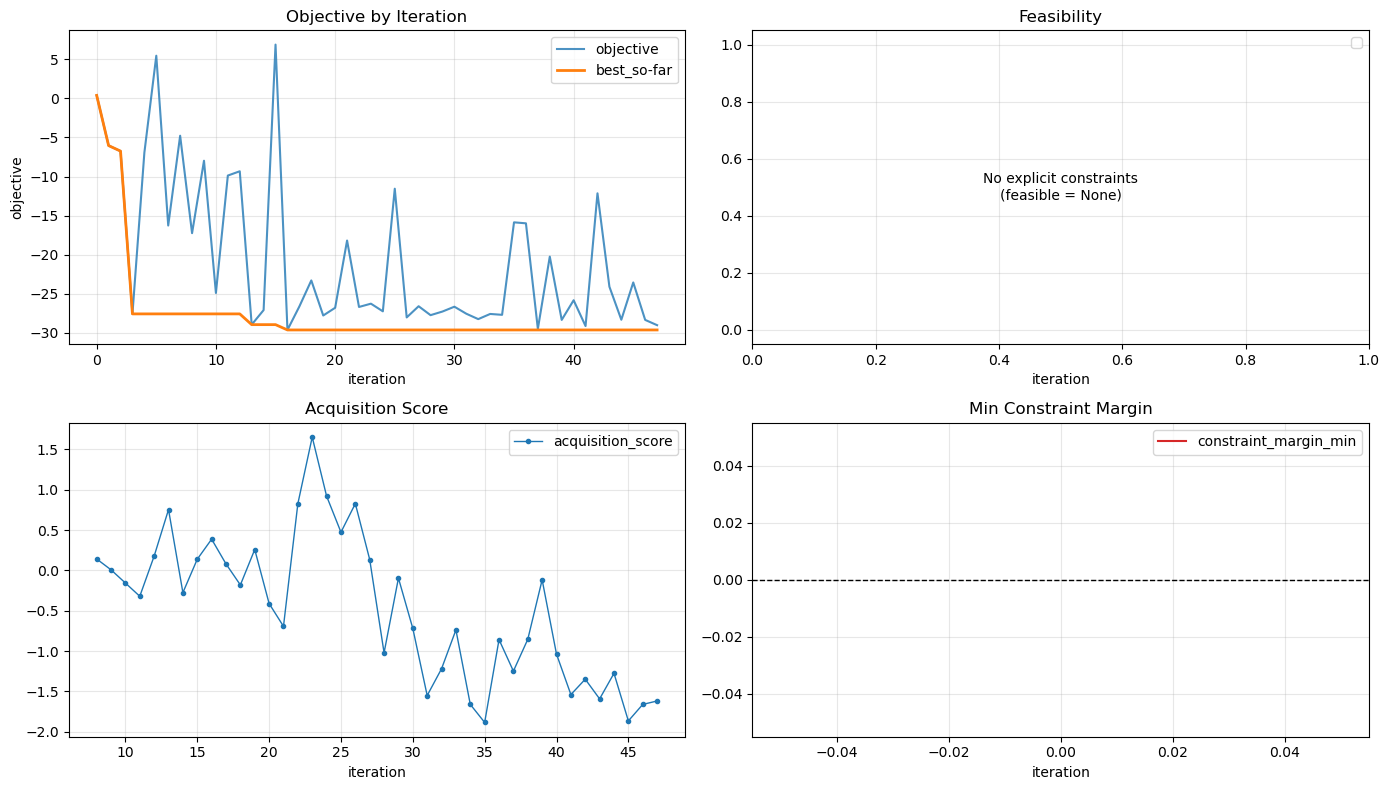

In [36]:
import matplotlib.pyplot as plt

if 'history_df' not in globals():
    history_df = pd.read_csv(result.recorder_output.csv_path)

plot_df = history_df.copy()
if 'iteration' in plot_df.columns:
    plot_df = plot_df.sort_values('iteration').reset_index(drop=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# 1) Objective and best-so-far
axes[0, 0].plot(plot_df['iteration'], plot_df['objective'], label='objective', alpha=0.8)
if 'best_so_far' in plot_df.columns:
    axes[0, 0].plot(plot_df['iteration'], plot_df['best_so_far'], label='best_so-far', linewidth=2)
axes[0, 0].set_title('Objective by Iteration')
axes[0, 0].set_xlabel('iteration')
axes[0, 0].set_ylabel('objective')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2) Feasibility trace + cumulative feasible ratio
if 'feasible' in plot_df.columns:
    feasible_raw = plot_df['feasible']
    feasible_bool = feasible_raw.map(lambda v: None if pd.isna(v) else bool(v))
    valid_mask = feasible_bool.notna()
    if valid_mask.any():
        feasible_num = feasible_bool[valid_mask].astype(int)
        cum_ratio = feasible_num.cumsum() / np.arange(1, len(feasible_num) + 1)
        iter_valid = plot_df.loc[valid_mask, 'iteration']
        axes[0, 1].step(iter_valid, feasible_num, where='post', label='feasible (0/1)', alpha=0.7)
        axes[0, 1].plot(iter_valid, cum_ratio, label='cumulative feasible ratio', linewidth=2)
    else:
        axes[0, 1].text(0.5, 0.5, 'No explicit constraints\n(feasible = None)',
                        ha='center', va='center', transform=axes[0, 1].transAxes)
axes[0, 1].set_title('Feasibility')
axes[0, 1].set_xlabel('iteration')
axes[0, 1].set_ylim(-0.05, 1.05)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3) Acquisition score
if 'acquisition_score' in plot_df.columns:
    acq = pd.to_numeric(plot_df['acquisition_score'], errors='coerce')
    axes[1, 0].plot(plot_df['iteration'], acq, marker='o', markersize=3, linewidth=1, label='acquisition_score')
axes[1, 0].set_title('Acquisition Score')
axes[1, 0].set_xlabel('iteration')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4) Constraint margin (higher is better; >=0 means feasible)
if 'constraint_margin_min' in plot_df.columns:
    axes[1, 1].plot(plot_df['iteration'], plot_df['constraint_margin_min'], color='tab:red', label='constraint_margin_min')
    axes[1, 1].axhline(0.0, color='black', linestyle='--', linewidth=1)
axes[1, 1].set_title('Min Constraint Margin')
axes[1, 1].set_xlabel('iteration')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
# Summary print for paper/debug
num_trials = len(history_df)
num_feasible = int(history_df['feasible'].sum()) if 'feasible' in history_df.columns else None
best_obj = float(history_df['objective'].min()) if num_trials else None
best_feasible_obj = None
if 'feasible' in history_df.columns and num_feasible and num_feasible > 0:
    best_feasible_obj = float(history_df.loc[history_df['feasible'] == True, 'objective'].min())

print('num_trials =', num_trials)
print('num_feasible_trials =', num_feasible)
print('best_objective =', best_obj)
print('best_feasible_objective =', best_feasible_obj)

num_trials = 48
num_feasible_trials = 0
best_objective = -29.642446245707813
best_feasible_objective = None


In [38]:
# Decomposition for penalized BCLF objective
# J = S_score - 5*P, while optimizer objective stores -J (minimization).

def _find_col(df, key):
    for c in df.columns:
        if key in c:
            return c
    return None

col_a_mean = _find_col(history_df, 'metric_s21_mean_5200000000_5900000000')
col_b_mean = _find_col(history_df, 'metric_s11_mean_5200000000_5900000000')
col_c_mean = _find_col(history_df, 'metric_s21_mean_union_3600000000_4800000000__6500000000_8700000000')

col_a_worst = _find_col(history_df, 'metric_s21_min_5200000000_5900000000')
col_b_worst = _find_col(history_df, 'metric_s11_max_5200000000_5900000000')
col_c_worst = _find_col(history_df, 'metric_s21_max_union_3600000000_4800000000__6500000000_8700000000')

required = [col_a_mean, col_b_mean, col_c_mean, col_a_worst, col_b_worst, col_c_worst]
if any(c is None for c in required):
    print('Missing decomposition columns:', required)
else:
    d = history_df.copy()
    d['a_mean'] = d[col_a_mean]
    d['b_mean'] = d[col_b_mean]
    d['c_mean'] = d[col_c_mean]
    d['a_worst'] = d[col_a_worst]
    d['b_worst'] = d[col_b_worst]
    d['c_worst'] = d[col_c_worst]

    d['S_score'] = d['a_mean'] - 0.5 * d['b_mean'] - 0.5 * d['c_mean']
    d['pen_a'] = ( -7.0 - d['a_worst'] ).clip(lower=0.0)
    d['pen_b'] = ( d['b_worst'] + 7.0 ).clip(lower=0.0)
    d['pen_c'] = ( d['c_worst'] + 18.0 ).clip(lower=0.0)
    d['P'] = d['pen_a'] + d['pen_b'] + d['pen_c']
    d['J'] = d['S_score'] - 5.0 * d['P']
    d['objective_should_be_neg_J'] = -d['J']

    cols = ['iteration', 'objective', 'objective_should_be_neg_J', 'S_score', 'pen_a', 'pen_b', 'pen_c', 'P', 'J']
    display(d[cols].head(20))


,iteration,objective,objective_should_be_neg_J,S_score,pen_a,pen_b,pen_c,P,J
0,0,0.389889,0.389889,26.914824,0.450944,5.009998,0.0,5.460943,-0.389889
1,1,-6.036880,-4.201777,27.164549,0.000000,4.592554,0.0,4.592554,4.201777
2,2,-6.745180,-1.893242,27.570108,0.000000,5.135373,0.0,5.135373,1.893242
3,3,-27.586046,-17.586046,28.541286,0.000000,2.191048,0.0,2.191048,17.586046
4,4,-6.946744,-5.247167,27.404620,0.000000,4.431491,0.0,4.431491,5.247167
5,5,5.468702,5.468702,26.547395,1.074832,5.328388,0.0,6.403219,-5.468702
6,6,-16.272946,-8.381183,28.842215,0.000000,4.092206,0.0,4.092206,8.381183
7,7,-4.774801,-0.262445,25.744492,0.000000,5.096409,0.0,5.096409,0.262445
8,8,-17.250523,-7.250523,28.269348,0.000000,4.203765,0.0,4.203765,7.250523
9,9,-7.977413,-3.962926,26.414692,0.000000,4.490353,0.0,4.490353,3.962926


## BO vs Random Baseline

Run `ReplayOptimizer` and `RandomSearchOptimizer` under the same settings and compare `best_so_far` convergence.

In [39]:
# Same setup for fair comparison
run_id_bo = f"{RUN_ID}_bo"
run_id_rand = f"{RUN_ID}_random"

# Use same initial/candidate pools and seed
sim_bo = ReplaySimulator(dataset=dataset)
sim_rand = ReplaySimulator(dataset=dataset)

rec_bo = ExperimentRecorder(output_dir=OUTPUT_DIR)
rec_rand = ExperimentRecorder(output_dir=OUTPUT_DIR)

opt_bo = ReplayOptimizer(
    dataset=dataset,
    simulator=sim_bo,
    objective=objective,
    recorder=rec_bo,
    initial_indices=initial_indices,
    candidate_indices=candidate_indices,
    budget=BUDGET,
    retrain_every=RETRAIN_EVERY,
    n_init=N_INIT,
    seed=SEED,
    run_id=run_id_bo,
    verbose=VERBOSE,
    print_every=PRINT_EVERY,
)

opt_rand = RandomSearchOptimizer(
    dataset=dataset,
    simulator=sim_rand,
    objective=objective,
    recorder=rec_rand,
    initial_indices=initial_indices,
    candidate_indices=candidate_indices,
    budget=BUDGET,
    n_init=N_INIT,
    seed=SEED,
    run_id=run_id_rand,
    verbose=VERBOSE,
    print_every=PRINT_EVERY,
)

result_bo = opt_bo.run()
result_rand = opt_rand.run()

print('BO best objective:', result_bo.state.best_objective)
print('Random best objective:', result_rand.state.best_objective)
print('BO csv:', result_bo.recorder_output.csv_path)
print('Random csv:', result_rand.recorder_output.csv_path)

BO best objective: -29.642446245707813
Random best objective: -27.586046098326975
BO csv: /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_latest_nb_bo.csv
Random csv: /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_latest_nb_random.csv


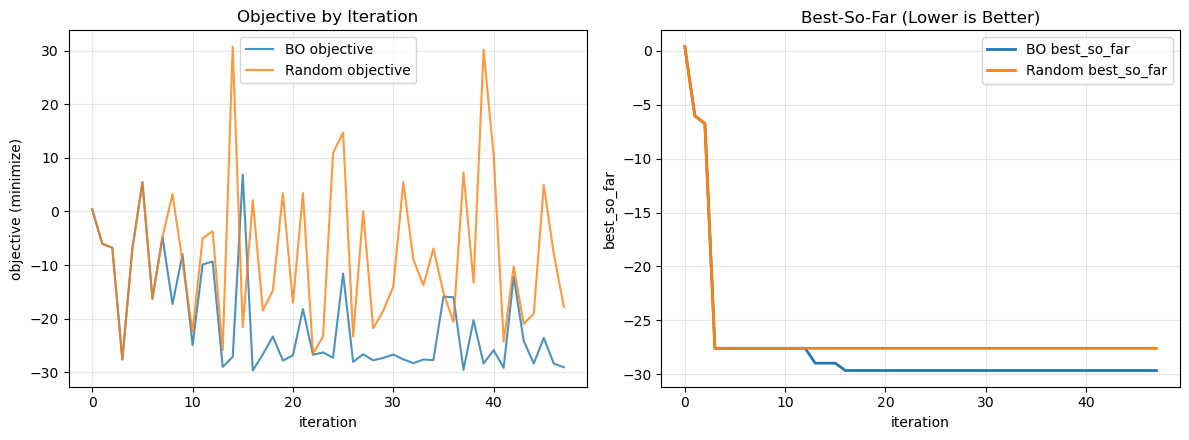

In [40]:
import matplotlib.pyplot as plt

df_bo = pd.read_csv(result_bo.recorder_output.csv_path).sort_values('iteration').reset_index(drop=True)
df_rand = pd.read_csv(result_rand.recorder_output.csv_path).sort_values('iteration').reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Per-iteration objective (non-monotonic)
axes[0].plot(df_bo['iteration'], df_bo['objective'], label='BO objective', alpha=0.8)
axes[0].plot(df_rand['iteration'], df_rand['objective'], label='Random objective', alpha=0.8)
axes[0].set_title('Objective by Iteration')
axes[0].set_xlabel('iteration')
axes[0].set_ylabel('objective (minimize)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Convergence signal
axes[1].plot(df_bo['iteration'], df_bo['best_so_far'], label='BO best_so_far', linewidth=2)
axes[1].plot(df_rand['iteration'], df_rand['best_so_far'], label='Random best_so_far', linewidth=2)
axes[1].set_title('Best-So-Far (Lower is Better)')
axes[1].set_xlabel('iteration')
axes[1].set_ylabel('best_so_far')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()